# 03. Experimentación Sistemática, Optuna, Stacking y MLflow (TF1 - CC209)

**Objetivo:** Superar las limitaciones de experimentación del TP1 (una sola partición 70/15/15, hiperparámetros manuales y dos familias básicas) mediante:
1. **Ablation Study** de Ingeniería de Características (`TelcoFeatureEngineer`) sin *data leakage*.
2. **Optimización Bayesiana con Optuna** (25 trials/familia en `StratifiedKFold k=5`) para Regresión Logística, Random Forest, LightGBM y XGBoost.
3. **Stacking Heterogéneo** (`LR + LGBM + XGB` con meta-clasificador logístico).
4. **Comparación justa en `StratifiedKFold (k=10)`** reportando $\mu \pm \sigma$ y pruebas pareadas de **Wilcoxon**.
5. **Trazabilidad en MLflow local**, exportada en `reports/mlflow_experimentos_tf1.csv`.

> **Regla anti-leakage:** Toda esta etapa opera exclusivamente sobre `Train + Validation` (5,986 filas). El bloque `Test` (1,057 filas) permanece completamente reservado.

In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.config import REPORTS_DIR, MODELS_DIR, FIGURES_TF1_DIR
from src.preprocessing import get_dev_and_test_splits

X_dev, X_test, y_dev, y_test = get_dev_and_test_splits()
print(f"Train+Val (Dev): {len(X_dev)} filas | Churn: {y_dev.mean():.2%}")
print(f"Test Holdout (bloqueado en esta etapa): {len(X_test)} filas | Churn: {y_test.mean():.2%}")

Train+Val (Dev): 5986 filas | Churn: 26.53%
Test Holdout (bloqueado en esta etapa): 1057 filas | Churn: 26.58%


## 1. Ablation Study de Feature Engineering (`TelcoFeatureEngineer`)

Verificamos en CV 5-fold si las 8 variables de negocio derivadas fila por fila (`TotalServicesSubscribed`, `BillingRatio`, `AvgMonthlyCharge`, `ChargeDelta`, `HighRisk_Fiber_No_Support`, `AutoPayFlag`, `ContractRiskTier`, `TenureBucket`) aportan señal y estabilidad.

In [2]:
df_ablation = pd.read_csv(REPORTS_DIR / "ablation_feature_engineering_tf1.csv")
display(df_ablation.round(4))

,Modelo_Base,Feature_Engineering_TF1,PR_AUC_Media,PR_AUC_Std
0,LogisticRegression,False,0.6566,0.0239
1,LogisticRegression,True,0.6602,0.0220
2,LightGBM,False,0.6462,0.0164
3,LightGBM,True,0.6428,0.0088


**Interpretación:**
- **Lo que muestran los datos:** En `LogisticRegression`, incorporar el *Feature Engineering* elevó el PR-AUC medio de `0.6566` a `0.6602` y redujo la desviación estándar (`0.0239 -> 0.0220`). En `LightGBM` sin afinar, el PR-AUC medio pasó de `0.6462` a `0.6428`, pero su desviación estándar entre folds cayó casi a la mitad (`0.0164 -> 0.0088`).
- **Interpretación técnica:** Las variables explícitas de interacción (`HighRisk_Fiber_No_Support`, `ContractRiskTier`) ayudan directamente a los modelos lineales que no capturan interacciones no lineales por sí solos y estabilizan la varianza entre particiones.

## 2. Optimización Bayesiana con Optuna e Hiperparámetros Óptimos

Scores Optuna CV 5-fold (PR-AUC):
  - logistic_regression : 0.6615
  - random_forest       : 0.6594
  - lightgbm            : 0.6670
  - xgboost             : 0.6680

Mejores hiperparámetros por familia:
{
  "logistic_regression": {
    "C": 0.7956749229281326,
    "l1_ratio": 0.8875152379959901,
    "class_weight": null
  },
  "random_forest": {
    "n_estimators": 400,
    "max_depth": 11,
    "min_samples_leaf": 12,
    "max_features": "sqrt",
    "class_weight": null
  },
  "lightgbm": {
    "n_estimators": 450,
    "learning_rate": 0.012707942999213693,
    "num_leaves": 24,
    "max_depth": 3,
    "min_child_samples": 26,
    "subsample": 0.7860370513913187,
    "colsample_bytree": 0.7085396127095583,
    "reg_alpha": 0.7838134236608698,
    "reg_lambda": 0.0060780830996819525,
    "scale_pos_weight": 2.77
  },
  "xgboost": {
    "n_estimators": 300,
    "learning_rate": 0.023750875411808082,
    "max_depth": 2,
    "min_child_weight": 10,
    "subsample": 0.8183885046672651,
   

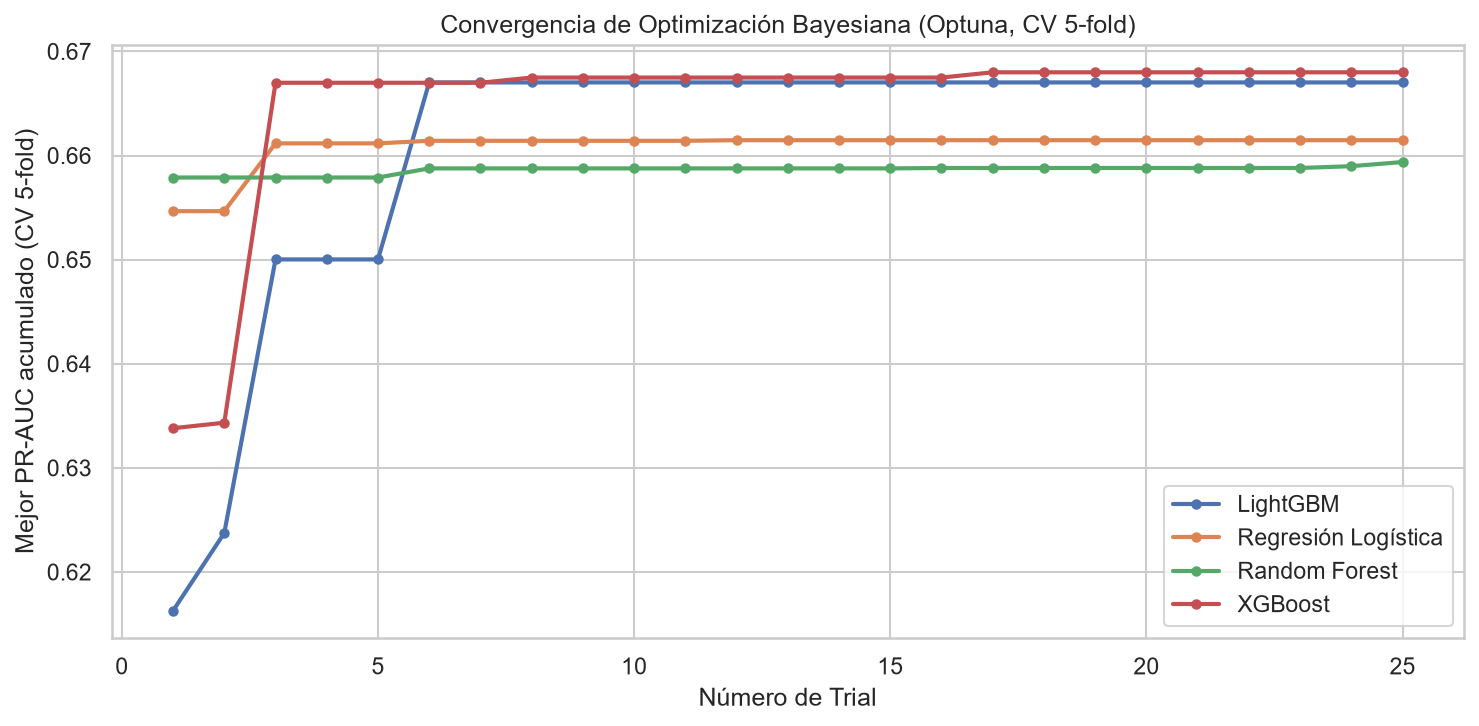

In [3]:
with open(MODELS_DIR / "best_params_tf1.json", "r", encoding="utf-8") as f:
    best_cfg = json.load(f)

print("Scores Optuna CV 5-fold (PR-AUC):")
for k, v in best_cfg["optuna_cv5_scores"].items():
    print(f"  - {k:20s}: {v:.4f}")

print("\nMejores hiperparámetros por familia:")
print(json.dumps(best_cfg["best_params_by_family"], indent=2))
display(Image(filename=str(FIGURES_TF1_DIR / "optuna_convergencia_tf1.png")))

**Interpretación:** El tuning sistemático con TPE (Optuna) impulsó a los algoritmos de *Gradient Boosting* (`XGBoost = 0.6680`, `LightGBM = 0.6670`) por encima de Random Forest (`0.6594`) y Regresión Logística (`0.6615`). Destaca que árboles poco profundos (`max_depth = 2` en XGBoost y `max_depth = 3` en LightGBM) con tasa de aprendizaje baja (`0.0127–0.0238`) evitaron el sobreajuste.

## 3. Comparación en `StratifiedKFold (k=10)` y Stacking Heterogéneo

,Modelo,PR-AUC_Mean,PR-AUC_Std,ROC-AUC_Mean,Recall (Clase 1)_Mean,Brier Score_Mean,Valor Económico Neto ($)_Mean
0,Stacking Heterogéneo (LR+LGBM+XGB),0.6732,0.0289,0.8515,0.5516,0.1333,-7145.0
1,XGBoost (Optuna),0.6724,0.0278,0.8513,0.5094,0.1330,-12630.0
2,LightGBM (Optuna),0.6716,0.0287,0.8508,0.8073,0.1603,23615.0
3,Regresión Logística (Optuna),0.6664,0.0332,0.8483,0.5308,0.1342,-9795.0
4,Random Forest (Optuna),0.6633,0.0311,0.8472,0.5050,0.1347,-13275.0
5,Baseline Heurístico (Mes-a-Mes & Tenure <= 6),0.3837,0.0191,0.6454,0.4138,0.2459,-26260.0
6,Baseline Trivial (Dummy),0.2653,0.0006,0.5000,0.0000,0.2653,-79400.0


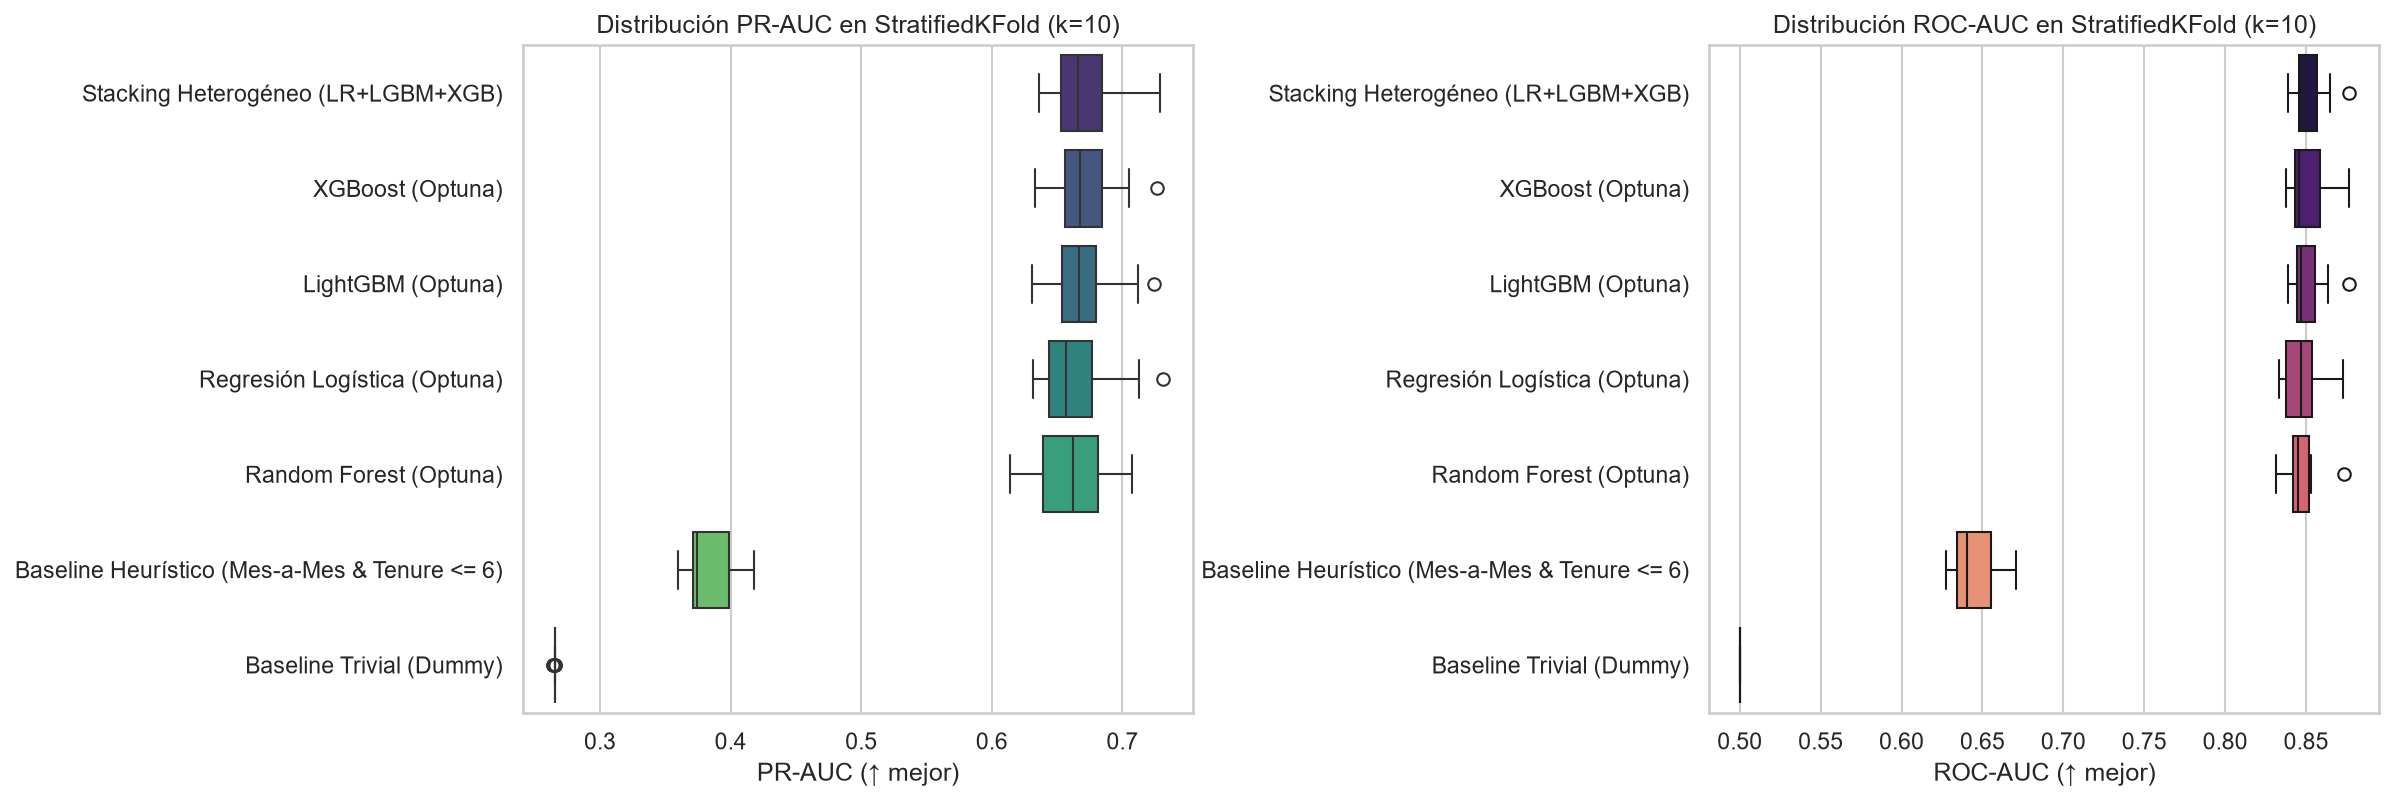

In [4]:
df_cv = pd.read_csv(REPORTS_DIR / "comparacion_modelos_cv_tf1.csv")
cols = [
    "Modelo", "PR-AUC_Mean", "PR-AUC_Std", "ROC-AUC_Mean",
    "Recall (Clase 1)_Mean", "Brier Score_Mean", "Valor Económico Neto ($)_Mean"
]
display(df_cv[cols].round(4))
display(Image(filename=str(FIGURES_TF1_DIR / "cv_comparacion_modelos_tf1.png")))

**Interpretación:**
- **Stacking Heterogéneo (`LR+LGBM+XGB`)** obtiene el mayor promedio de `PR-AUC = 0.6732 ± 0.0289` y `ROC-AUC = 0.8515`, manteniendo un excelente `Brier Score = 0.1333`.
- **Observación crítica sobre el umbral `0.50`:** A diferencia de `LightGBM (Optuna)` —donde Optuna eligió `scale_pos_weight = 2.77` obteniendo `Recall = 80.7%` pero `Brier Score = 0.1603`—, `Stacking`, `XGBoost` y `LR` producen probabilidades mejor calibradas pero conservadoras respecto al corte `0.50` (`Recall = 50.9%–55.2%`), lo que motiva directamente la optimización del umbral de decisión en el Notebook 04.

## 4. Significancia Estadística (Wilcoxon Pareado) y Tracking MLflow

In [5]:
df_wil = pd.read_csv(REPORTS_DIR / "wilcoxon_cv_tf1.csv")
display(df_wil.round(5))

df_mlflow = pd.read_csv(REPORTS_DIR / "mlflow_experimentos_tf1.csv")
print(f"Total de corridas trazadas en MLflow: {len(df_mlflow)}")
cols_mlf = [
    c for c in [
        "tags.mlflow.runName", "tags.stage", "metrics.pr_auc_mean",
        "metrics.roc_auc_mean", "metrics.brier_score_mean"
    ]
    if c in df_mlflow.columns
]
display(
    df_mlflow[cols_mlf]
    .dropna(subset=["metrics.pr_auc_mean"])
    .sort_values("metrics.pr_auc_mean", ascending=False)
)

,Modelo_Referencia,Modelo_Comparado,Delta_PR_AUC_Media,Wilcoxon_Stat,Wilcoxon_p_value,TTest_Stat,TTest_p_value,Significativo_alpha_0.05
0,Stacking Heterogéneo (LR+LGBM+XGB),XGBoost (Optuna),0.00073,23.0,0.69531,0.53359,0.60655,False
1,Stacking Heterogéneo (LR+LGBM+XGB),LightGBM (Optuna),0.00156,17.0,0.32227,1.16686,0.27325,False
2,Stacking Heterogéneo (LR+LGBM+XGB),Regresión Logística (Optuna),0.00679,6.0,0.02734,2.60598,0.02846,True
3,Stacking Heterogéneo (LR+LGBM+XGB),Random Forest (Optuna),0.00984,0.0,0.00195,3.80542,0.00418,True


Total de corridas trazadas en MLflow: 11


,tags.mlflow.runName,tags.stage,metrics.pr_auc_mean,metrics.roc_auc_mean,metrics.brier_score_mean
6,cv10_Stacking Heterogéneo (LR+LGBM+XGB),cv10_comparative,0.673155,0.851463,0.133315
5,cv10_XGBoost (Optuna),cv10_comparative,0.672423,0.851263,0.133042
4,cv10_LightGBM (Optuna),cv10_comparative,0.671599,0.850839,0.160302
3,cv10_Regresión Logística (Optuna),cv10_comparative,0.666366,0.848256,0.134181
2,cv10_Random Forest (Optuna),cv10_comparative,0.663313,0.847173,0.134731
1,cv10_Baseline Heurístico (Mes-a-Mes & Tenure <...,cv10_comparative,0.383672,0.645375,0.245898
0,cv10_Baseline Trivial (Dummy),cv10_comparative,0.265286,0.500000,0.265285


**Conclusión estadística de la Fase 3:**
- Frente a `Random Forest (Optuna)` (`p = 0.00195`) y `Regresión Logística (Optuna)` (`p = 0.02734`), la mejora de **Stacking Heterogéneo** es **estadísticamente significativa** ($\alpha = 0.05$).
- Frente a `XGBoost` (`p = 0.695`) y `LightGBM` (`p = 0.322`), la diferencia en PR-AUC medio no es estadísticamente significativa, aunque Stacking lidera ambas métricas de discriminación (`PR-AUC = 0.6732`, `ROC-AUC = 0.8515`) y avanza como candidato a la etapa de calibración y umbrales.